In [330]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
DATA_FILE = "data_02a.xlsx"
RANDOM_SEED = 42

In [331]:
print('\nPreviewing data_02a.xlsx:')
df_excel = pd.read_excel(DATA_FILE)
print(df_excel.head())


Previewing data_02a.xlsx:
      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90


In [332]:
FEATURE_NAMES = ("AT", "V", "AP", "RH")
TARGET_NAME = "PE"

In [333]:
import os
OUTPUT_DIR = "/content/"

MULTIVARIATE_CONFIG = {
    "file_path": str(DATA_FILE),
    "sheet_names": ["Sheet1"],
    "validation_fraction": 0.2,
    "learning_rate": 0.1,
    "iterations": 1000,
    "unscaled_learning_rate": 1e-6,
    "unscaled_iterations": 100_000,
}

In [334]:
def load_power_plant_data(filepath, sheet_names):
    all_data = []
    for sheet_name in sheet_names:
        dataframe = pd.read_excel(filepath, sheet_name=sheet_name)
        expected_header = FEATURE_NAMES + (TARGET_NAME,)
        if tuple(dataframe.columns) != expected_header:
            raise ValueError(
                f"Expected columns {expected_header}, found {tuple(dataframe.columns)} in sheet {sheet_name}"
            )
        all_data.append(dataframe.to_numpy(dtype=np.float64))

    data = np.concatenate(all_data, axis=0)

    if data.ndim != 2 or data.shape[1] != 5 or not np.isfinite(data).all():
        raise ValueError("Power plant data must contain five numeric columns")

    x = data[:, :4]
    y = data[:, 4].reshape(-1, 1)
    print(f"[INFO] Loaded {x.shape[0]} samples from {filepath} (sheets {sheet_names})")
    return x, y

In [335]:
x, y = load_power_plant_data(
    filepath=MULTIVARIATE_CONFIG["file_path"],
    sheet_names=MULTIVARIATE_CONFIG["sheet_names"],
)

[INFO] Loaded 9568 samples from data_02a.xlsx (sheets ['Sheet1'])


In [336]:
print("First 5 feature rows:")
print(pd.DataFrame(x[:5], columns=FEATURE_NAMES).to_string(index=False))
print(f"Feature matrix shape (samples, features): {x.shape}")

First 5 feature rows:
   AT     V      AP    RH
14.96 41.76 1024.07 73.17
25.18 62.96 1020.04 59.08
 5.11 39.40 1012.16 92.14
20.86 57.32 1010.24 76.64
10.82 37.50 1009.23 96.62
Feature matrix shape (samples, features): (9568, 4)


In [337]:
print("First 5 target values:")
print(pd.DataFrame(y[:5], columns=[TARGET_NAME]).to_string(index=False))
print(f"Target array shape (samples, targets): {y.shape}")

First 5 target values:
    PE
463.26
444.37
488.56
446.48
473.90
Target array shape (samples, targets): (9568, 1)


In [338]:
def save_plot(filepath):
    plt.tight_layout()
    plt.savefig(filepath, dpi=150)
    print(f"[INFO] Plot saved to {filepath}")
    plt.show()
    plt.close()

In [339]:
def plot_features(x, y):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for index, (axis, name) in enumerate(zip(axes.flat, FEATURE_NAMES)):
        axis.scatter(x[:, index], y[:, 0], s=6, alpha=0.35)
        axis.set_title(f"{name} vs {TARGET_NAME}")
        axis.set_xlabel(name)
        axis.set_ylabel(TARGET_NAME)
        axis.grid(True, alpha=0.3)
    fig.suptitle("Power Plant: Features and Electrical Output")
    save_plot(os.path.join(OUTPUT_DIR, "power_plant_features.png"))

[INFO] Plot saved to /content/power_plant_features.png


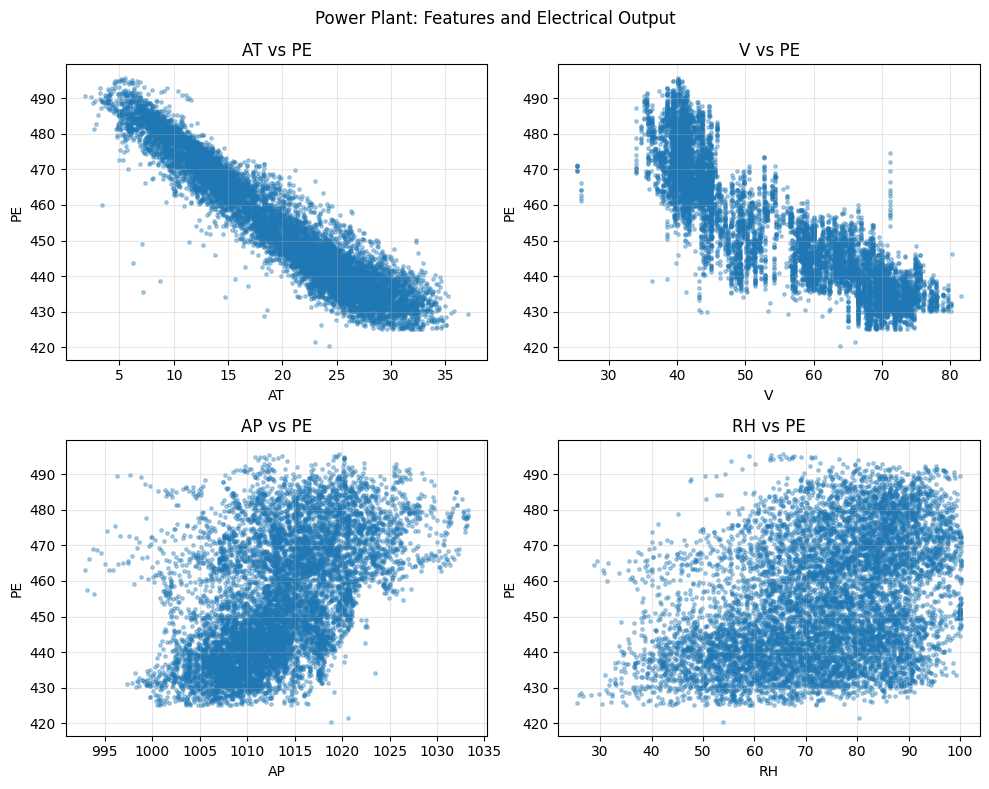

In [340]:
plot_features(x,y)

In [341]:
def split_data(x, y, validation_fraction):
    random_generator = np.random.default_rng(RANDOM_SEED)
    indices = random_generator.permutation(x.shape[0])
    validation_count = max(1, round(x.shape[0] * validation_fraction))
    if validation_count >= x.shape[0]:
        raise ValueError("At least one training sample is required")

    validation_indices = indices[:validation_count]
    training_indices = indices[validation_count:]
    return (
        x[training_indices],
        y[training_indices],
        x[validation_indices],
        y[validation_indices],
    )

In [342]:
def process_data(x_values, y_values, feature_scaling, scaling_params=None, verbose=True):
    num_samples = x_values.shape[0]
    processed_x = x_values.copy()

    if scaling_params is None:
        scaling_params = {
            "mean": np.zeros(x_values.shape[1]),
            "std": np.ones(x_values.shape[1]),
            "scaled": feature_scaling,
        }
        if feature_scaling:
            feature_mean = np.mean(processed_x, axis=0)
            feature_std = np.std(processed_x, axis=0)
            feature_std = np.where(feature_std == 0, 1.0, feature_std)
            scaling_params["mean"] = feature_mean
            scaling_params["std"] = feature_std
            if verbose:
                print("  Scaling statistics (training data):")
                print(f"    {'Feature':<7}{'Mean':>10}{'Std':>10}")
                for name, mean_value, std_value in zip(FEATURE_NAMES, feature_mean, feature_std):
                    print(f"    {name:<7}{mean_value:>10.4f}{std_value:>10.4f}")

    if feature_scaling:
        processed_x = (processed_x - scaling_params["mean"]) / scaling_params["std"]

    design_matrix = np.column_stack((np.ones(num_samples), processed_x))
    target_vector = y_values.reshape(-1, 1)
    return design_matrix, target_vector, scaling_params

In [343]:
def compute_cost(X, y, theta):
    m = X.shape[0]
    predictions = X @ theta
    errors = predictions - y
    cost = (1.0 / (2 * m)) * np.sum(errors**2)
    return cost

In [344]:
def gradient_descent(
    X,
    y,
    theta,
    alpha,
    num_iters,
    X_validation=None,
    y_validation=None
):
    m = X.shape[0]

    training_cost_history = []
    validation_cost_history = []

    best_theta = theta.copy()
    best_validation_cost = np.inf
    best_training_cost = np.inf
    best_iteration = 0

    for iteration in range(1, num_iters + 1):


        predictions = X @ theta


        errors = predictions - y


        gradient = (1.0 / m) * (X.T @ errors)

        theta = theta - alpha * gradient


        training_cost = compute_cost(X, y, theta)

        if not np.isfinite(training_cost):
            raise FloatingPointError("Gradient descent diverged")

        training_cost_history.append(training_cost)

        if X_validation is not None and y_validation is not None:

            validation_cost = compute_cost(
                X_validation,
                y_validation,
                theta
            )

            if not np.isfinite(validation_cost):
                raise FloatingPointError(
                    "Validation cost diverged"
                )

            validation_cost_history.append(validation_cost)

            if validation_cost < best_validation_cost:
                best_validation_cost = validation_cost
                best_training_cost = training_cost
                best_theta = theta.copy()
                best_iteration = iteration


    if X_validation is None:
        best_theta = theta.copy()
        best_training_cost = training_cost_history[-1]
        best_iteration = num_iters
        best_validation_cost = None

    return {
        "theta": best_theta,
        "best_iteration": best_iteration,
        "training_cost": best_training_cost,
        "validation_cost": best_validation_cost,
        "training_history": training_cost_history,
        "validation_history": validation_cost_history
    }

In [345]:
def train(x_train, y_train, x_validation, y_validation, feature_scaling,
          learning_rate, num_iters, verbose=True, record_validation_curve=False):
    if verbose:
        print(f"  {'Learning rate':<15}: {learning_rate:g}")
        print(f"  {'Iterations':<15}: {num_iters:,}")
    X_train, y_train_vector, scaling_params = process_data(
        x_train, y_train, feature_scaling, verbose=verbose
    )
    X_validation, y_validation_vector, _ = process_data(
        x_validation, y_validation, feature_scaling, scaling_params=scaling_params
    )
    theta = np.zeros((X_train.shape[1], 1))

    gd_result = gradient_descent(
        X_train, y_train_vector, theta, learning_rate, num_iters,
        X_validation=X_validation if record_validation_curve else None,
        y_validation=y_validation_vector if record_validation_curve else None,
    )

    theta = gd_result['theta']
    training_cost_history = gd_result['training_history']
    validation_cost_history = gd_result['validation_history']

    training_mse = 2 * training_cost_history[-1]

    validation_cost = (
        validation_cost_history[-1] if record_validation_curve
        else compute_cost(X_validation, y_validation_vector, theta)
    )
    validation_mse = 2 * validation_cost

    best_iteration = gd_result['best_iteration']
    best_validation_mse = 2 * gd_result['validation_cost'] if gd_result['validation_cost'] is not None else None
    best_training_mse = 2 * gd_result['training_cost']

    if verbose:
        print(f"  {'Training MSE':<15}: {training_mse:.4f}")
        print(f"  {'Validation MSE':<15}: {validation_mse:.4f}")
        if best_iteration is not None:
            print(f"  {'Best val MSE':<15}: {best_validation_mse:.4f} "
                  f"(iteration {best_iteration:,}; training MSE {best_training_mse:.4f})")

    return {
        "theta": theta,
        "cost_history": training_cost_history,
        "validation_cost_history": validation_cost_history,
        "training_mse": training_mse,
        "validation_mse": validation_mse,
        "best_iteration": best_iteration,
        "best_validation_mse": best_validation_mse,
        "best_training_mse": best_training_mse,
        "scaling_params": scaling_params,
    }

In [346]:
def original_linear_parameters(result):
    theta = result["theta"].ravel()
    mean = result["scaling_params"]["mean"]
    std = result["scaling_params"]["std"]
    slopes = theta[1:] / std
    intercept = theta[0] - np.sum(theta[1:] * mean / std)
    return np.concatenate(([intercept], slopes))

In [347]:
def print_linear_parameters(result):
    parameters = original_linear_parameters(result)
    print("[INFO] Learned parameters in original feature units:")
    print(f"  intercept = {parameters[0]:.6f}")
    for name, value in zip(FEATURE_NAMES, parameters[1:]):
        print(f"  {name:>9} = {value:.6f}")

In [348]:
def plot_cost_curve(result, title, filename):
    training_cost = np.asarray(result["cost_history"])
    validation_cost = np.asarray(result["validation_cost_history"])
    if len(training_cost) != len(validation_cost):
        raise ValueError("Training and validation cost histories must have the same length")
    iterations = np.arange(1, len(training_cost) + 1)
    zoom_start = max(0, int(0.8 * len(iterations)) - 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].plot(iterations, training_cost, label="Training", linewidth=1.5)
    axes[0].plot(iterations, validation_cost, label="Validation", linewidth=1.5)
    axes[0].set_yscale("log")
    axes[0].set_title("All iterations (log scale)")

    axes[1].plot(iterations[zoom_start:], training_cost[zoom_start:],
                 label="Training", linewidth=1.5)
    axes[1].plot(iterations[zoom_start:], validation_cost[zoom_start:],
                 label="Validation", linewidth=1.5)
    axes[1].set_title("Last 20% of iterations")
    axes[1].legend()

    for axis in axes:
        axis.set_xlabel("Iteration")
        axis.set_ylabel("Cost")
        axis.grid(True, alpha=0.3)
    fig.suptitle(title)
    save_plot(os.path.join(OUTPUT_DIR, filename))

In [349]:
def print_box_table(headers, rows, right_align=()):
    widths = [max(len(str(value)) for value in column) for column in zip(headers, *rows)]
    border = "+" + "+".join("-" * (width + 2) for width in widths) + "+"

    def format_row(values):
        cells = []
        for index, (value, width) in enumerate(zip(values, widths)):
            text = str(value)
            cells.append(text.rjust(width) if index in right_align else text.ljust(width))
        return "| " + " | ".join(cells) + " |"

    print(border)
    print(format_row(headers))
    print(border)
    for row in rows:
        print(format_row(row))
    print(border)

In [350]:
def run_multivariate_data():
    config = MULTIVARIATE_CONFIG
    print("\n" + "=" * 60)
    print("  PART A: LINEAR REGRESSION WITH MULTIPLE VARIABLES")
    print("=" * 60 + "\n")

    x, y = load_power_plant_data(config["file_path"], config["sheet_names"])
    x_train, y_train, x_validation, y_validation = split_data(
        x, y, config["validation_fraction"]
    )

    comparison = []
    for feature_scaling, label, filename in (
        (False, "Without Feature Scaling", "multivariate_unscaled_cost.png"),
        (True, "With Feature Scaling", "multivariate_scaled_cost.png"),
    ):
        print(f"\n--- {label} ---")
        learning_rate = config["learning_rate"] if feature_scaling else config["unscaled_learning_rate"]
        iterations = config["iterations"] if feature_scaling else config["unscaled_iterations"]
        result = train(
            x_train, y_train, x_validation, y_validation,
            feature_scaling=feature_scaling,
            learning_rate=learning_rate, num_iters=iterations,
            record_validation_curve=True,
        )
        plot_cost_curve(result, f"Power Plant: {label}", filename)
        comparison.append((label, result["training_mse"], result["validation_mse"]))
        if feature_scaling:
            scaled_result = result
        else:
            unscaled_result = result

    print("\nPart A comparison (MSE)")
    mse_rows = [
        (label, f"{training_mse:.4f}", f"{validation_mse:.4f}")
        for label, training_mse, validation_mse in comparison
    ]
    print_box_table(("Run", "Training MSE", "Validation MSE"), mse_rows, right_align=(1, 2))

    unscaled_theta = original_linear_parameters(unscaled_result)
    scaled_theta = original_linear_parameters(scaled_result)
    normalized_theta = scaled_result["theta"].ravel()
    parameter_names = ("theta_0 (intercept)",) + tuple(f"theta_{name}" for name in FEATURE_NAMES)
    theta_rows = [
        (name, f"{unscaled_value:.6f}", f"{scaled_value:.6f}", f"{normalized_value:.6f}")
        for name, unscaled_value, scaled_value, normalized_value in zip(
            parameter_names, unscaled_theta, scaled_theta, normalized_theta
        )
    ]
    print("\nPart A theta comparison")
    print_box_table(
        ("Parameter", "No scaling", "Scaled, original", "Scaled, normalized"),
        theta_rows,
        right_align=(1, 2, 3),
    )

    return x, y, unscaled_result, scaled_result


  PART A: LINEAR REGRESSION WITH MULTIPLE VARIABLES

[INFO] Loaded 9568 samples from data_02a.xlsx (sheets ['Sheet1'])

--- Without Feature Scaling ---
  Learning rate  : 1e-06
  Iterations     : 100,000
  Training MSE   : 28.2142
  Validation MSE : 29.3126
  Best val MSE   : 29.3126 (iteration 100,000; training MSE 28.2142)
[INFO] Plot saved to /content/multivariate_unscaled_cost.png


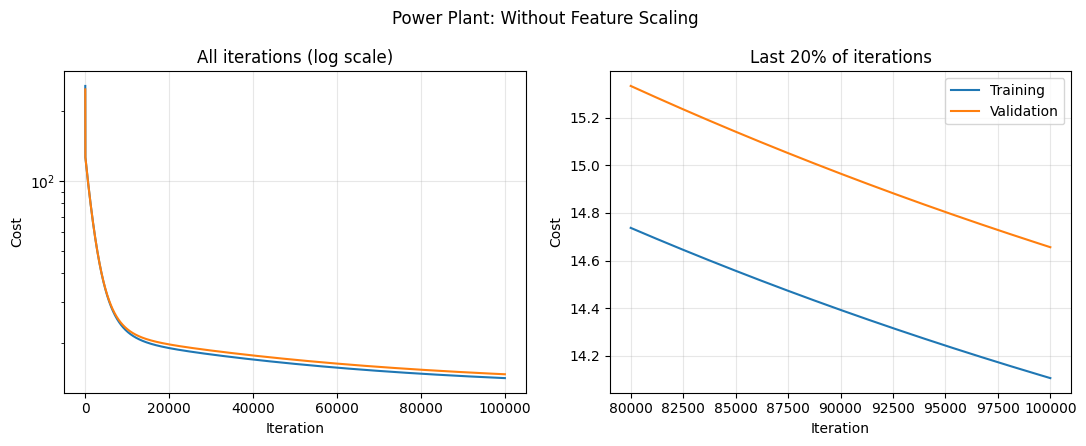


--- With Feature Scaling ---
  Learning rate  : 0.1
  Iterations     : 1,000
  Scaling statistics (training data):
    Feature      Mean       Std
    AT        19.7064    7.4534
    V         54.3874   12.7042
    AP      1013.2297    5.8874
    RH        73.3224   14.6140
  Training MSE   : 20.9579
  Validation MSE : 20.0303
  Best val MSE   : 20.0303 (iteration 1,000; training MSE 20.9579)
[INFO] Plot saved to /content/multivariate_scaled_cost.png


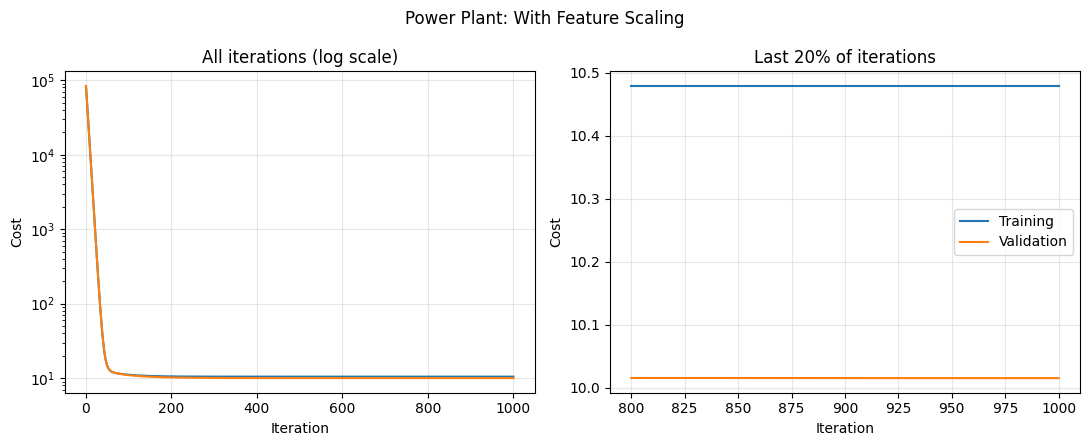


Part A comparison (MSE)
+-------------------------+--------------+----------------+
| Run                     | Training MSE | Validation MSE |
+-------------------------+--------------+----------------+
| Without Feature Scaling |      28.2142 |        29.3126 |
| With Feature Scaling    |      20.9579 |        20.0303 |
+-------------------------+--------------+----------------+

Part A theta comparison
+---------------------+------------+------------------+--------------------+
| Parameter           | No scaling | Scaled, original | Scaled, normalized |
+---------------------+------------+------------------+--------------------+
| theta_0 (intercept) |   0.000755 |       445.461755 |         454.247651 |
| theta_AT            |  -1.170263 |        -1.957245 |         -14.588186 |
| theta_V             |  -0.512659 |        -0.242731 |          -3.083706 |
| theta_AP            |   0.500193 |         0.071046 |           0.418280 |
| theta_RH            |  -0.022178 |        -0.1558

In [351]:
x, y, unscaled_result, scaled_result = run_multivariate_data()

In [352]:
FEATURE_NAME = 'Feature'
TARGET_NAME = 'Target'
DATA_FILE = "data_02b.csv"
POLYNOMIAL_CONFIG = {
    'file_path': str(DATA_FILE),
    'degrees': (1, 2, 3),
    'validation_fraction': 0.2,
    'learning_rate': 0.01,
    'iterations': 2000,
}

In [353]:
def load_polynomial_data(filepath):
    dataframe = pd.read_csv(filepath, header=None)
    if dataframe.shape[1] != 2:
        raise ValueError('Expected exactly two CSV columns: feature and target')
    data = dataframe.to_numpy(dtype=np.float64)
    if data.ndim != 2 or data.shape[0] < 2 or not np.isfinite(data).all():
        raise ValueError('The CSV must contain at least two rows of finite numeric values')
    x = data[:, 0]
    y = data[:, 1].reshape(-1, 1)
    print(f'[INFO] Loaded {len(x)} samples from {filepath}')
    return x, y

In [354]:
x, y = load_polynomial_data(POLYNOMIAL_CONFIG['file_path'])
print(pd.DataFrame({FEATURE_NAME: x[:5], TARGET_NAME: y[:5, 0]}).to_string(index=False))
print(f'Feature shape: {x.shape}  |  Target shape: {y.shape}')

[INFO] Loaded 392 samples from data_02b.csv
 Feature  Target
   130.0    18.0
   165.0    15.0
   150.0    18.0
   150.0    16.0
   140.0    17.0
Feature shape: (392,)  |  Target shape: (392, 1)


In [355]:
def save_plot(filepath):
    plt.tight_layout()
    plt.savefig(filepath, dpi=150)
    print(f'[INFO] Plot saved to {filepath}')
    plt.show()
    plt.close()

In [356]:
def plot_raw_data(x, y):
    plt.figure(figsize=(9, 5.5))
    plt.scatter(x, y[:, 0], s=18, alpha=0.6, color='tab:blue')
    plt.title('Part C - Raw Data (data_02b.csv)')
    plt.xlabel(FEATURE_NAME)
    plt.ylabel(TARGET_NAME)
    plt.grid(True, alpha=0.3)
    save_plot(os.path.join(OUTPUT_DIR, 'polynomial_raw_data.png'))

[INFO] Plot saved to /content/polynomial_raw_data.png


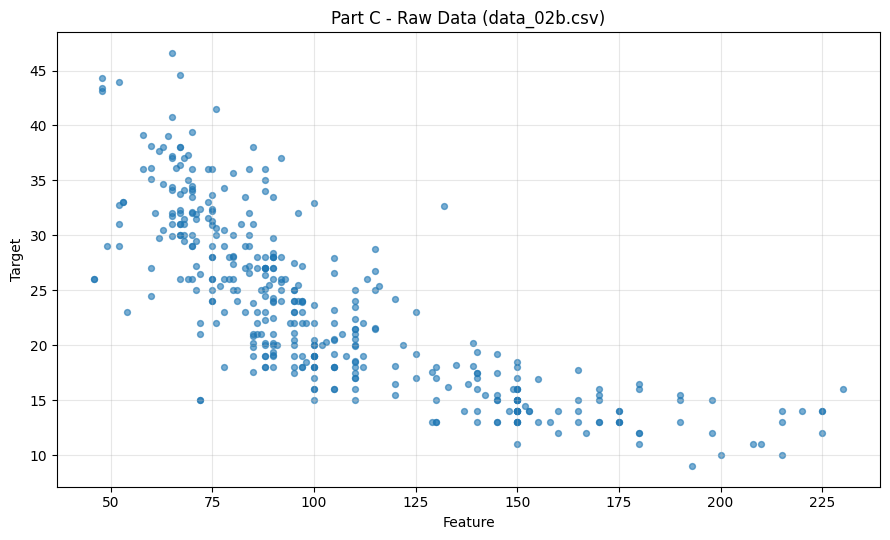

In [357]:
plot_raw_data(x, y)

In [358]:
def split_data(x, y, validation_fraction):
    random_generator = np.random.default_rng(RANDOM_SEED)
    indices = random_generator.permutation(len(x))
    validation_count = max(1, round(len(x) * validation_fraction))
    if validation_count >= len(x):
        raise ValueError('At least one training sample is required')
    validation_indices = indices[:validation_count]
    training_indices = indices[validation_count:]
    return x[training_indices], y[training_indices], x[validation_indices], y[validation_indices]

In [359]:
def process_data(x_values, degree, scaling_params=None):
    x_values = np.asarray(x_values, dtype=np.float64).reshape(-1)
    if scaling_params is None:
        feature_mean = float(np.mean(x_values))
        feature_std = float(np.std(x_values))
        if feature_std == 0:
            raise ValueError('The training feature has zero standard deviation')
        scaling_params = {'mean': feature_mean, 'std': feature_std}

    scaled_x = (x_values - scaling_params['mean']) / scaling_params['std']
    design_matrix = np.column_stack([scaled_x**power for power in range(degree + 1)])
    return design_matrix, scaling_params

In [360]:
def compute_cost(X, y, theta):
    m = X.shape[0]
    predictions = X @ theta
    errors = predictions - y
    cost = (1.0 / (2 * m)) * np.sum(errors**2)
    return cost

In [361]:
def train_polynomial(x_train, y_train, x_validation, y_validation,
                     degree, learning_rate, num_iters):
    X_train, scaling_params = process_data(x_train, degree)
    X_validation, _ = process_data(x_validation, degree, scaling_params)
    theta = np.zeros((X_train.shape[1], 1))

    gd_result = gradient_descent(
        X_train, y_train, theta, learning_rate, num_iters,
        X_validation=X_validation,
        y_validation=y_validation,
    )

    return {
        'degree': degree,
        'theta': gd_result['theta'],
        'best_iteration': gd_result['best_iteration'],
        'training_mse': 2 * gd_result['training_cost'],
        'validation_mse': 2 * gd_result['validation_cost'],
        'training_cost_history': gd_result['training_history'],
        'validation_cost_history': gd_result['validation_history'],
        'scaling_params': scaling_params,
    }

In [362]:
def print_box_table(headers, rows, right_align=()):
    widths = [max(len(str(value)) for value in column) for column in zip(headers, *rows)]
    border = '+' + '+'.join('-' * (width + 2) for width in widths) + '+'

    def format_row(values):
        cells = []
        for index, (value, width) in enumerate(zip(values, widths)):
            text = str(value)
            cells.append(text.rjust(width) if index in right_align else text.ljust(width))
        return '| ' + ' | '.join(cells) + ' |'

    print(border)
    print(format_row(headers))
    print(border)
    for row in rows:
        print(format_row(row))
    print(border)

In [363]:
def plot_polynomial_fits(x, y, results):
    colors = {1: 'blue', 2: 'green', 3: 'red'}
    x_curve = np.linspace(np.min(x), np.max(x), 400)
    plt.figure(figsize=(9, 5.5))
    plt.scatter(x, y[:, 0], s=17, alpha=0.45, color='gray', label='Data')
    for degree, result in results.items():
        X_curve, _ = process_data(x_curve, degree, result['scaling_params'])
        y_curve = X_curve @ result['theta']
        plt.plot(x_curve, y_curve[:, 0], color=colors[degree], linewidth=2,
                 label=f'd={degree} (val MSE={result["validation_mse"]:.2f})')
    plt.title('Part C - Polynomial Regression Fits (d = 1, 2, 3)')
    plt.xlabel(FEATURE_NAME)
    plt.ylabel(TARGET_NAME)
    plt.grid(True, alpha=0.3)
    plt.legend()
    save_plot(os.path.join(OUTPUT_DIR, 'polynomial_fits.png'))

In [364]:
def plot_degree_errors(results):
    degrees = sorted(results.keys())
    training_errors = [results[d]['training_mse'] for d in degrees]
    validation_errors = [results[d]['validation_mse'] for d in degrees]

    x = np.arange(len(degrees))
    width = 0.35

    fig, ax = plt.subplots(figsize=(9, 5.5))
    rects1 = ax.bar(x - width/2, training_errors, width, label='Training MSE', color='tab:blue', alpha=0.8)
    rects2 = ax.bar(x + width/2, validation_errors, width, label='Validation MSE', color='tab:orange', alpha=0.8)

    ax.set_ylabel('Mean Squared Error (MSE)')
    ax.set_xlabel('Polynomial Degree (d)')
    ax.set_title('Part C - Training and Validation Error by Degree')
    ax.set_xticks(x)
    ax.set_xticklabels([f'd = {d}' for d in degrees])
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    for rects in [rects1, rects2]:
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom')

    save_plot(os.path.join(OUTPUT_DIR, 'polynomial_degree_errors.png'))

In [365]:
def plot_cost_curves(results):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
    for axis, (degree, result) in zip(axes, results.items()):
        iterations = np.arange(1, len(result['training_cost_history']) + 1)
        axis.plot(iterations, result['training_cost_history'], label='Training', linewidth=1.5)
        axis.plot(iterations, result['validation_cost_history'], label='Validation', linewidth=1.5)
        axis.axvline(result['best_iteration'], color='magenta', linestyle=':', linewidth=1,
                     label='Best iteration')
        axis.set_title(f'd = {degree}')
        axis.set_xlabel('Iteration')
        axis.set_yscale('log')
        axis.grid(True, alpha=0.3)
        axis.legend(fontsize=8)
    axes[0].set_ylabel('Cost')
    fig.suptitle('Part C - Training and Validation Cost by Degree')
    save_plot(os.path.join(OUTPUT_DIR, 'polynomial_cost_curves.png'))

In [366]:
def run_polynomial_regression(x, y):
    config = POLYNOMIAL_CONFIG
    print('\n' + '=' * 60)
    print('  PART B: POLYNOMIAL REGRESSION')
    print('=' * 60 + '\n')
    x_train, y_train, x_validation, y_validation = split_data(
        x, y, config['validation_fraction']
    )
    _, scaling_params = process_data(x_train, degree=1)
    print(f'  Training samples   : {len(x_train)}')
    print(f'  Validation samples : {len(x_validation)}')
    print(f'  Learning rate      : {config["learning_rate"]:g}')
    print(f'  Iterations         : {config["iterations"]:,}')
    print(f'  Training feature mean/std: {scaling_params["mean"]:.4f} / {scaling_params["std"]:.4f}')

    results = {}
    for degree in config['degrees']:
        results[degree] = train_polynomial(
            x_train, y_train, x_validation, y_validation,
            degree, config['learning_rate'], config['iterations'],
        )
    rows = [
        (f'd = {degree}', str(result['best_iteration']),
         f'{result["training_mse"]:.4f}', f'{result["validation_mse"]:.4f}')
        for degree, result in results.items()
    ]
    print('\nDegree comparison (MSE at each degree\'s best iteration)')
    print_box_table(
        ('Degree', 'Best iteration', 'Training MSE', 'Validation MSE'),
        rows, right_align=(1, 2, 3),
    )

    best_degree = min(results, key=lambda degree: results[degree]['validation_mse'])
    best_result = results[best_degree]
    print(f'\nBest degree: d = {best_degree} '
          f'(validation MSE = {best_result["validation_mse"]:.4f})')
    for degree, result in results.items():
        normalized_theta = result['theta'].ravel()
        # original_theta = original_polynomial_parameters(result)
        parameter_rows = [
            (f'theta_{power}', f'{normalized:.6f}') #, f'{original:.9f}')
            for power, normalized in enumerate(
                # zip(normalized_theta, original_theta)
                normalized_theta
            )
        ]
        best_label = ' (best degree)' if degree == best_degree else ''
        print(f'\nLearned parameters for d = {degree}{best_label} '
              f'| best iteration {result["best_iteration"]}')
        print_box_table(
            ('Parameter', 'Normalized feature'), #, 'Original feature units'),
            parameter_rows, right_align=(1,), #, 2),
        )

    plot_polynomial_fits(x, y, results)
    plot_degree_errors(results)
    plot_cost_curves(results)
    return results, best_degree


  PART B: POLYNOMIAL REGRESSION

  Training samples   : 314
  Validation samples : 78
  Learning rate      : 0.01
  Iterations         : 2,000
  Training feature mean/std: 106.7102 / 38.6280

Degree comparison (MSE at each degree's best iteration)
+--------+----------------+--------------+----------------+
| Degree | Best iteration | Training MSE | Validation MSE |
+--------+----------------+--------------+----------------+
| d = 1  |           2000 |      23.0927 |        27.4567 |
| d = 2  |            973 |      18.4220 |        21.3379 |
| d = 3  |            920 |      18.8650 |        20.6995 |
+--------+----------------+--------------+----------------+

Best degree: d = 3 (validation MSE = 20.6995)

Learned parameters for d = 1 | best iteration 2000
+-----------+--------------------+
| Parameter | Normalized feature |
+-----------+--------------------+
| theta_0   |          23.002548 |
| theta_1   |          -6.005161 |
+-----------+--------------------+

Learned parameters fo

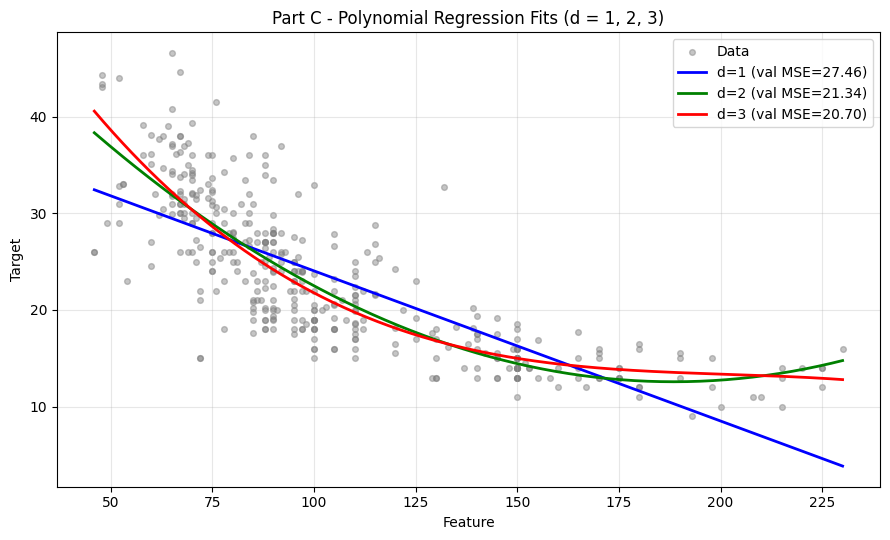

[INFO] Plot saved to /content/polynomial_degree_errors.png


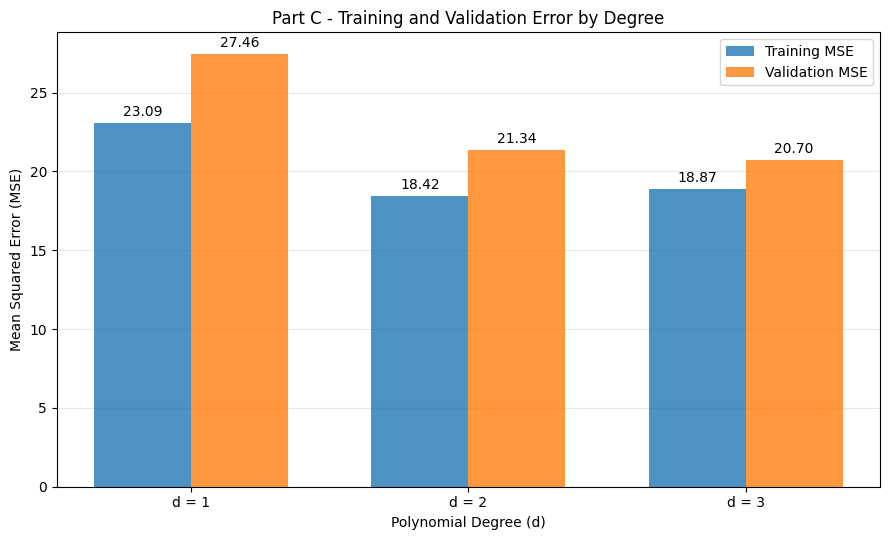

[INFO] Plot saved to /content/polynomial_cost_curves.png


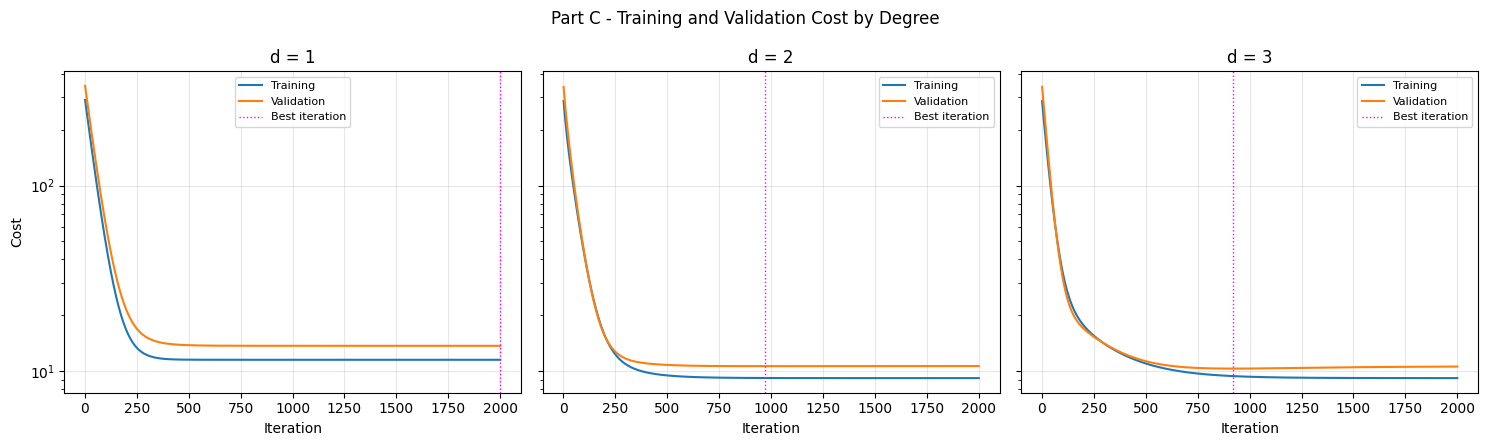

In [367]:
results, best_degree = run_polynomial_regression(x, y)